In [1]:
import pandas as pd
import numpy as np
import re

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import joblib

In [2]:
feedback = [
    # Positive feedback
    "I love the teaching method",
    "The teacher explains everything clearly",
    "I really enjoy studying this subject",
    "The classes are very interesting",
    "My performance has improved a lot",
    "The teacher is very supportive",
    "I understand every topic easily",
    "The learning experience is excellent",
    "I am happy with my academic progress",
    "The study material is very helpful",
    "The teacher makes learning enjoyable",
    "I feel confident about my exams",
    "The lectures are informative",
    "I am satisfied with my results",
    "The classroom environment is excellent",
    "I have improved my learning skills",
    "The explanations are very helpful",
    "I enjoy solving practice questions",
    "The course is well organized",
    "I am excited to learn new topics",

    # Negative feedback
    "I cannot understand mathematics",
    "The teaching method is confusing",
    "I am struggling with my studies",
    "The lectures are very boring",
    "I performed badly in my exams",
    "The study material is difficult",
    "I need help understanding the topics",
    "I am unhappy with my academic progress",
    "The teacher explains too quickly",
    "I have difficulty solving questions",
    "The classroom environment is distracting",
    "I am worried about my examination",
    "I do not understand the lessons",
    "My grades are getting worse",
    "The course is very difficult",
    "I feel stressed about studying",
    "The explanations are not clear",
    "I cannot complete my assignments",
    "I am disappointed with my results",
    "I need more support from teachers",

    # Neutral feedback
    "The class was conducted today",
    "I attended the mathematics lecture",
    "The examination is scheduled next week",
    "We studied a new chapter today",
    "The teacher assigned homework",
    "I completed my classroom assignment",
    "The lecture lasted for one hour",
    "We discussed the examination schedule",
    "The syllabus contains five chapters",
    "I submitted my assignment today",
    "The class started at nine o'clock",
    "We have a test next Monday",
    "The teacher shared the notes",
    "I studied two chapters today",
    "The examination has twenty questions",
    "We received our academic timetable",
    "The homework contains ten questions",
    "The lecture covered algebra",
    "I attended the computer science class",
    "The next lecture is on Friday"
]

sentiments = (
    ["Positive"] * 20 +
    ["Negative"] * 20 +
    ["Neutral"] * 20
)

df = pd.DataFrame({
    "feedback": feedback,
    "sentiment": sentiments
})

df.head()

,feedback,sentiment
0,I love the teaching method,Positive
1,The teacher explains everything clearly,Positive
2,I really enjoy studying this subject,Positive
3,The classes are very interesting,Positive
4,My performance has improved a lot,Positive


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

Dataset Shape: (60, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   feedback   60 non-null     str  
 1   sentiment  60 non-null     str  
dtypes: str(2)
memory usage: 1.1 KB

Missing Values:
feedback     0
sentiment    0
dtype: int64

Sentiment Distribution:
sentiment
Positive    20
Negative    20
Neutral     20
Name: count, dtype: int64


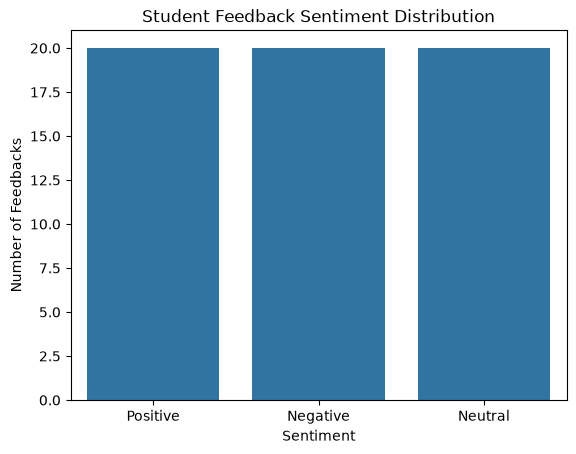

In [4]:
sns.countplot(data=df, x="sentiment")

plt.title("Student Feedback Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Feedbacks")

plt.show()

In [5]:
def clean_text(text):

    text = text.lower()

    text = re.sub(r"http\S+|www\S+", "", text)

    text = re.sub(r"[^a-zA-Z\s]", "", text)

    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["cleaned_feedback"] = df["feedback"].apply(clean_text)

df.head()

,feedback,sentiment,cleaned_feedback
0,I love the teaching method,Positive,i love the teaching method
1,The teacher explains everything clearly,Positive,the teacher explains everything clearly
2,I really enjoy studying this subject,Positive,i really enjoy studying this subject
3,The classes are very interesting,Positive,the classes are very interesting
4,My performance has improved a lot,Positive,my performance has improved a lot


In [6]:
X = df["cleaned_feedback"]

y = df["sentiment"]

print("Input Features:")
print(X.head())

print("\nTarget Labels:")
print(y.head())

Input Features:
0                 i love the teaching method
1    the teacher explains everything clearly
2       i really enjoy studying this subject
3           the classes are very interesting
4          my performance has improved a lot
Name: cleaned_feedback, dtype: str

Target Labels:
0    Positive
1    Positive
2    Positive
3    Positive
4    Positive
Name: sentiment, dtype: str


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 48
Testing Data: 12
